# Task 2 · Auto MPG regression pipeline

**Arrowstack Data Science · Azhar**

Predict historical city-cycle fuel efficiency using vehicle specifications.
The continuous target is `mpg`. This is regression, not classification.

[UCI Auto MPG source](https://archive.ics.uci.edu/dataset/9/auto+mpg)
· Quinlan, R. (1993), [DOI](https://doi.org/10.24432/C5859H), CC BY 4.0.

Protocol: hold out exact normalized car-name groups, compare fixed candidate
pipelines using five training-only group folds, freeze the selection, then evaluate
the selected model and naive baseline on the holdout. No model decisions use the
held-out test scores. This is a small historical benchmark, not a modern-car service.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_all.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
pd.set_option("display.max_columns", 20)

def show_saved_figure(path):
    fig, ax = plt.subplots(figsize=(13, 6))
    ax.imshow(plt.imread(path))
    ax.axis("off")
    fig.tight_layout()
    plt.show()

print("Project root found. Included source data will be used offline.")

Project root found. Included source data will be used offline.


## 1. Understand the target and predictors

In [2]:
from task2_regression.train import load_data, prepare_features, group_split, make_pipeline, candidate_models, train, FEATURES, TARGET
data = load_data()
X, y = prepare_features(data), data[TARGET]
print("X:", X.shape, "y:", y.shape)
print("Predictors:", FEATURES)
print(data.head().to_string(index=False))
print("\nMissing values:\n", data.isna().sum().to_string())
assert TARGET not in X.columns
assert "car_name" not in X.columns

X: (398, 7) y: (398,)
Predictors: ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin']
 source_row  mpg  cylinders  displacement  horsepower  weight  acceleration  model_year origin                  car_name
          1 18.0          8         307.0       130.0  3504.0          12.0          70    usa chevrolet chevelle malibu
          2 15.0          8         350.0       165.0  3693.0          11.5          70    usa         buick skylark 320
          3 18.0          8         318.0       150.0  3436.0          11.0          70    usa        plymouth satellite
          4 16.0          8         304.0       150.0  3433.0          12.0          70    usa             amc rebel sst
          5 17.0          8         302.0       140.0  3449.0          10.5          70    usa               ford torino

Missing values:
 source_row      0
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
mo

## 2. Reserve the grouped test set

The dataset contains repeated names. Exact names must stay in one partition.
The 20% test fraction applies to groups, so row counts need not be exactly 80/20.
Typos and related model names can still create dependence; this grouping is not
a guarantee that all vehicle families are independent.

In [3]:
train_ids, test_ids = group_split(data)
train_names = set(data.iloc[train_ids].car_name)
test_names = set(data.iloc[test_ids].car_name)
print("Training rows:", len(train_ids), "Test rows:", len(test_ids))
print("Training names:", len(train_names), "Test names:", len(test_names))
print("Name overlap:", len(train_names & test_names))
assert not train_names & test_names

Training rows: 321 Test rows: 77
Training names: 244 Test names: 61
Name overlap: 0


## 3. Build the preprocessing and candidate models

Numeric branch: median imputation, missing indicators, and scaling.
Categorical branch: most-frequent imputation and one-hot encoding with unknown
categories handled safely. All learned statistics fit inside each CV training fold.
The naive baseline predicts the training mean. Fixed candidates include Linear
Regression, Ridge, Random Forest, and Gradient Boosting.

In [4]:
candidates = candidate_models()
for name, estimator in candidates.items():
    print(name, "→", estimator)
print("\nExample complete pipeline:\n", make_pipeline(candidates["Ridge"]))

Dummy mean → DummyRegressor()
Linear regression → LinearRegression()
Ridge → Ridge(alpha=10.0)
Random forest → RandomForestRegressor(min_samples_leaf=2, n_estimators=200, n_jobs=1,
                      random_state=42)
Gradient boosting → GradientBoostingRegressor(learning_rate=0.05, max_depth=2, n_estimators=200,
                          random_state=42)

Example complete pipeline:
 Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 keep_empty_features=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                      

## 4. Run the full training workflow

Selection uses lowest mean training-fold RMSE. The code saves fold scores,
split assignments, test predictions, diagnostics, metadata, and the pipeline.
The saved model stays fitted on the training partition only. Results below are
computed by this run, not hardcoded examples.

Selected: Gradient boosting
Selection rule: lowest mean 5-fold group CV RMSE on training rows
            model  cv_rmse_mean_mpg  cv_rmse_std_mpg  cv_mae_mean_mpg  cv_r2_mean
Gradient boosting            2.7298           0.5212           2.0194      0.8722
    Random forest            2.7608           0.5017           1.9982      0.8700
Linear regression            3.2643           0.4081           2.5370      0.8204
            Ridge            3.3198           0.4146           2.5442      0.8147
       Dummy mean            7.7866           0.4087           6.5625     -0.0183

CV partition checks:
  fold  fit_rows  valid_rows  group_overlap
    1       256          65              0
    2       257          64              0
    3       257          64              0
    4       257          64              0
    5       257          64              0


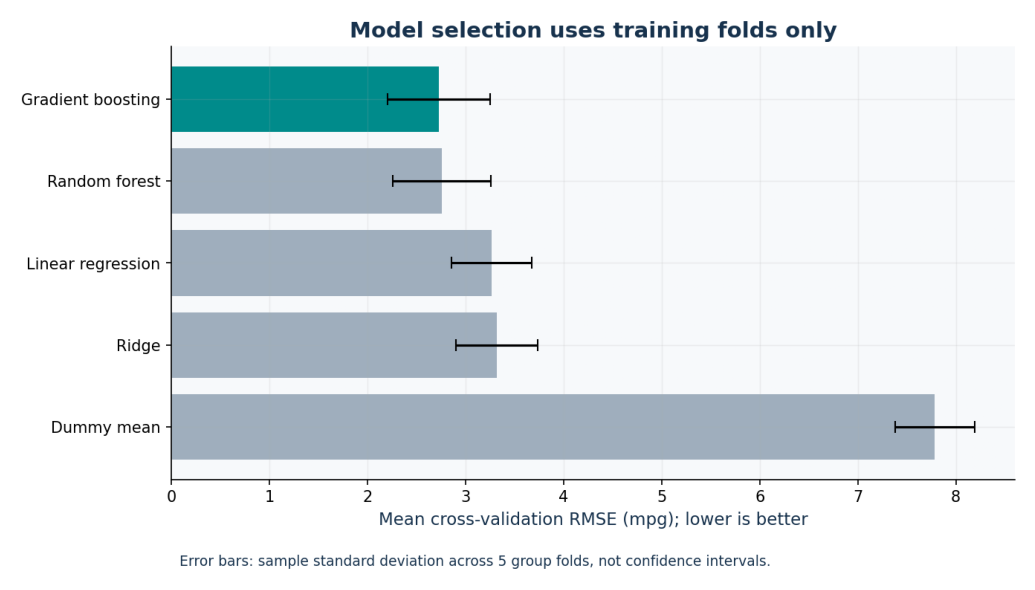

In [5]:
results = train()
REPORTS = ROOT / "task2_regression/reports"
print("Selected:", results["selected_model"])
print("Selection rule:", results["selection_metric"])
print(pd.read_csv(REPORTS / "model_comparison.csv").round(4).to_string(index=False))
print("\nCV partition checks:\n", pd.read_csv(REPORTS / "cv_split_checks.csv").to_string(index=False))
show_saved_figure(REPORTS / "figures/01_model_comparison.png")

## 5. Final holdout metrics

MAE: typical absolute error, in mpg. RMSE: error in mpg that emphasizes larger
misses. MSE: squared mpg. R²: variance-based performance relative to a mean
reference, not a classification accuracy percentage. The baseline uses the training
mean, while the R² definition uses the observed test mean in its denominator.

Selected model test metrics:
 {
  "mae_mpg": 1.9396998346144216,
  "mse_mpg_squared": 7.233304687671605,
  "rmse_mpg": 2.689480375030018,
  "r2": 0.8849239817817773
}
Training-mean baseline test metrics:
 {
  "mae_mpg": 6.47256544078974,
  "mse_mpg_squared": 63.28789731788769,
  "rmse_mpg": 7.955369087470907,
  "r2": -0.006859179754892031
}


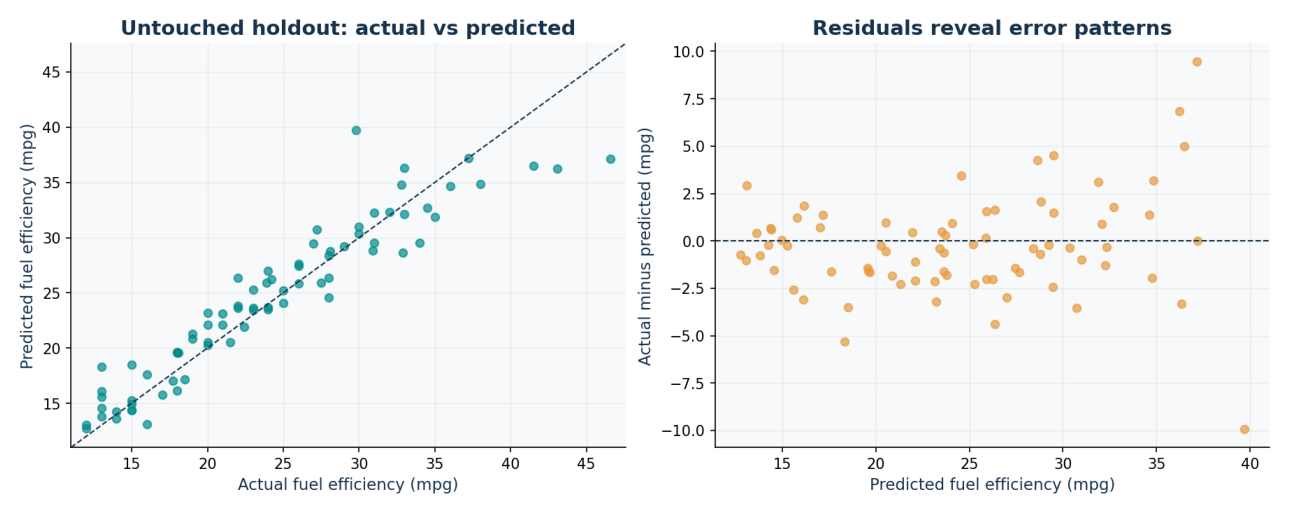

In [6]:
print("Selected model test metrics:\n", json.dumps(results["test_metrics"], indent=2))
print("Training-mean baseline test metrics:\n", json.dumps(results["test_baseline_metrics"], indent=2))
show_saved_figure(REPORTS / "figures/02_holdout_diagnostics.png")

## 6. Post-selection diagnostics

Inspect origin-specific errors and permutation importance after freezing the model.
Do not retune it using these holdout diagnostics and still call the same holdout
untouched. Correlated features can share importance; importance is not causation.

origin  test_rows  mae_mpg
europe         18    2.624
 japan         15    2.200
   usa         44    1.571

Feature importance:
      feature  rmse_increase_mean_mpg  rmse_increase_std_mpg
   cylinders                   0.122                  0.069
      origin                   0.129                  0.131
acceleration                   0.174                  0.083
displacement                   0.380                  0.115
  horsepower                   1.593                  0.197
  model_year                   2.698                  0.341
      weight                   3.110                  0.308


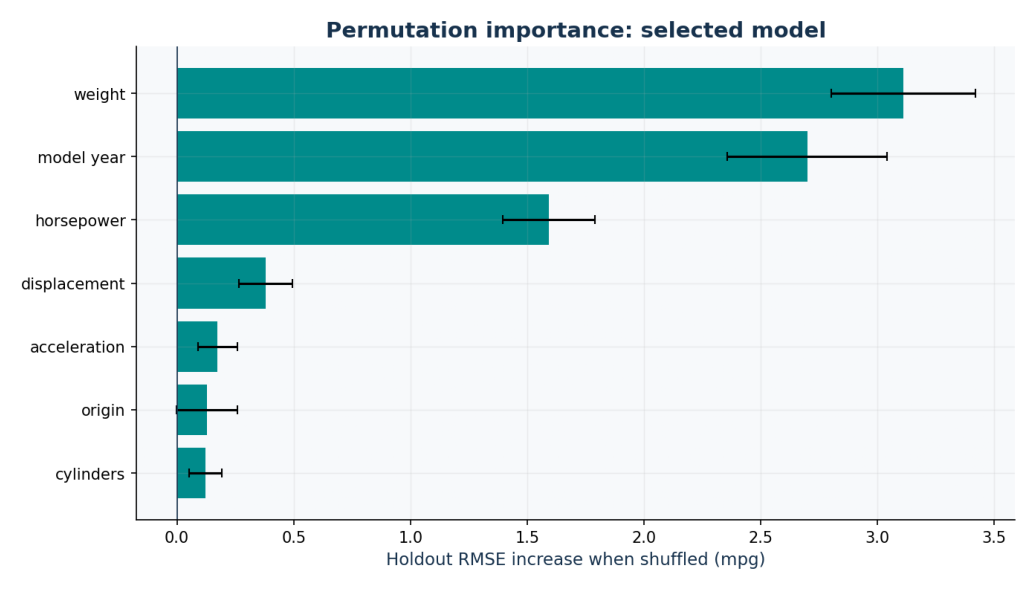

In [7]:
print(pd.read_csv(REPORTS / "errors_by_origin.csv").round(3).to_string(index=False))
print("\nFeature importance:\n", pd.read_csv(REPORTS / "permutation_importance.csv").round(3).to_string(index=False))
show_saved_figure(REPORTS / "figures/03_permutation_importance.png")

## 7. Reload the locally trained model and predict

The following input rows are **illustrative vehicle specifications**, not another
measured dataset. One horsepower value is deliberately blank to demonstrate the
trained imputer. Load only trusted joblib files: they can execute code.

In [8]:
import joblib
artifact = joblib.load(ROOT / "task2_regression/models/auto_mpg_pipeline.joblib")
example = pd.read_csv(ROOT / "task2_regression/examples/new_cars.csv")
example["predicted_mpg"] = artifact["pipeline"].predict(prepare_features(example))
print(example.round(3).to_string(index=False))
example.to_csv(REPORTS / "example_predictions.csv", index=False)

 cylinders  displacement  horsepower  weight  acceleration  model_year origin  predicted_mpg
         4           120        88.0    2500          15.5          79    usa         28.973
         4            97        67.0    2100          17.0          80  japan         35.874
         6           200         NaN    3100          16.0          78    usa         19.966


## 8. Limitations and next steps

- Model years are historical two-digit codes 70–82. Reject modern years.
- This random group split is not a forecast evaluation; consider a separate
  time-ordered study before making claims about future vehicles.
- A small holdout has uncertainty, and exact names do not identify every related model family.
- Unseen categories and out-of-range numeric inputs require review.
- No prediction intervals, deployment monitoring, or modern-car validation are included.

Read `reports/final_report.md`, `docs/data_dictionary.md`, and the repository's
beginner guide. Run `python -m unittest discover -s tests -v` for validation.
The binary model is generated locally and excluded from Git; the source data,
metadata, notebook outputs, and prediction results are versioned.